# NHL: анализ статистики команд

**Тестовое задание • 100 баллов**

Вы аналитик, которому передали готовую таблицу с исторической статистикой команд NHL.
Изучите данные, проверьте их, постройте графики и объясните свои наблюдения.
В работе оцениваются чтение данных, анализ, графики и обоснованность выводов.

Ориентир времени: 3-5 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами разместите на платформе githib.com.
Укажите имя, дату и используемые инструменты укажите в README.
Файл `data/hockey_raw.csv` уже приложен к заданию. Исходный файл сохраняйте без изменений.
Для развёрнутого ответа обычно достаточно 3-6 содержательных предложений.
Каждый такой ответ должен ссылаться на ваши числа, строки или графики.

## Данные

Одна строка соответствует одной команде в одном сезоне. Значение `year` является
меткой сезона на сайте. Источник готовой таблицы:
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/).
Работайте с приложенным CSV; обращения к сайту для выполнения задания не нужны.

| Столбец | Значение |
|---|---|
| `team` | Название команды |
| `year` | Метка сезона |
| `wins` | Победы |
| `losses` | Поражения |
| `ot_losses` | Поражения в дополнительное время, если значение указано |
| `win_rate` | Доля побед, указанная в источнике |
| `goals_for` | Забитые шайбы |
| `goals_against` | Пропущенные шайбы |
| `goal_diff` | Разница забитых и пропущенных шайб |

Пустое значение в `ot_losses` рассматривайте как пропуск.
Для графиков указывайте заголовок и подписи осей с единицами измерения.
При объяснении причин отделяйте то, что видно в таблице, от предположений.

## Баллы

| Раздел | Баллы |
|---|---:|
| 1. Загрузка и проверка | 25 |
| 2. Таблицы и группировка | 25 |
| 3. Графики | 30 |
| 4. Интерпретация | 20 |
| **Всего** | **100** |

Выполняйте пункты по порядку. Каждый пункт оценивается отдельно.

**Автор:** Васин Василий Андреевич
**Дата:** 13.10.26
**Использованные источники и инструменты:** Python 3.13, pandas, matplotlib, BeautifulSoup4, документация NHL Records; языковые модели использовались в качестве ассистента для рефакторинга кода визуализации и проверки гипотез.

In [3]:
# Ваши импорты и настройки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1.1. Загрузите таблицу: 5 баллов

Прочитайте приложенный CSV в pandas. Покажите первые пять строк,
        число строк и столбцов. Какие наблюдения представляет одна строка?

In [2]:
# 1.1. Ваш код
# Добавьте ячейки при необходимости.
df = pd.read_csv('data/hockey_raw.csv')
display(df.head())
print(f"Число строк: {df.shape[0]}, число столбцов: {df.shape[1]}")

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


Число строк: 582, число столбцов: 9


**Ответ 1.1:**

Таблица была успешно прочитана из файла data/hockey_raw.csv. Датасет содержит 582 строки и 9 столбцов. Одно наблюдение (одна строка) представляет собой агрегированную итоговую статистику выступления одной конкретной команды NHL за один сезон (year).

## 1.2. Разберитесь со столбцами: 6 баллов

Выведите названия и типы столбцов. Посчитайте число разных команд и годов.
        Проверьте, повторяется ли пара `team` и `year`. Объясните результат проверки.

In [5]:
# 1.2. Ваш код
# Добавьте ячейки при необходимости.
print("Столбцы и их типы:")
print(df.dtypes)
print("-" * 40)

unique_teams = df['team'].nunique()
unique_years = df['year'].nunique()
print(f"Уникальных команд: {unique_teams}")
print(f"Уникальных сезонов (лет): {unique_years}")

duplicates_count = df.duplicated(subset=['team', 'year']).sum()
print(f"Число дубликатов по паре ('team', 'year'): {duplicates_count}")

Столбцы и их типы:
team                 str
year               int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object
----------------------------------------
Уникальных команд: 35
Уникальных сезонов (лет): 21
Число дубликатов по паре ('team', 'year'): 0


**Ответ 1.2:**

В таблице представлены текстовый столбец team (название команды), целочисленные признаки year, wins, losses, goals_for, goals_against, goal_diff (int64), а также вещественные показатели win_rate и ot_losses (float64).   Всего в данных зафиксировано 35 уникальных команд и 21 уникальный сезон.   Число дубликатов по паре ('team', 'year') равно 0. Это подтверждает, что в рамках одного сезона каждая команда фиксируется в таблице ровно один раз, поэтому пара (team, year) является уникальным составным ключом датасета. 

## 1.3. Найдите пропуски: 8 баллов

Посчитайте число и долю пропусков по столбцам. Для `ot_losses` покажите
        число пропусков по годам. Как будете обращаться с этим полем в дальнейшем анализе
        и почему?

In [6]:
# 1.3. Ваш код
# Добавьте ячейки при необходимости.
# Число и доля пропусков по каждому столбцу
missing_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2)
})
display(missing_summary)

# Для ot_losses: число пропусков по годам
ot_missing_by_year = df[df['ot_losses'].isna()].groupby('year').size()
print("Годы, где есть пропуски в ot_losses, и их количество:")
print(ot_missing_by_year)

# Также посмотрим на годы, где ot_losses присутствуют
ot_present_by_year = df[df['ot_losses'].notna()].groupby('year').size()
print("\nСезоны с заполненным ot_losses:")
print(ot_present_by_year)

,missing_count,missing_pct
team,0,0.00
year,0,0.00
wins,0,0.00
losses,0,0.00
ot_losses,224,38.49
win_rate,0,0.00
goals_for,0,0.00
goals_against,0,0.00
goal_diff,0,0.00


Годы, где есть пропуски в ot_losses, и их количество:
year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
dtype: int64

Сезоны с заполненным ot_losses:
year
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
dtype: int64


**Ответ 1.3:**

В большинстве столбцов пропуски полностью отсутствуют (0 строк, 0%). Единственный столбец с пропусками - ot_losses, в котором пропущено 224 значения (38.49% от всех наблюдений датасета).Группировка показывает строгую историческую границу: с 1990 по 1998 год все команды имеют пропуски в ot_losses, тогда как начиная с 1999 года (и до 2011) показатель зафиксирован для всех команд без исключения. Это связано с изменением правил NHL - отдельный учет очков за поражения в дополнительное время появился только с сезона 1999/2000, а до этого фиксировались классические ничьи. В дальнейшем анализе заполнять пропуски нулями для ранних сезонов нельзя, так как это исказило бы спортивную картину (приравняло бы отсутствие правила к нулевому количеству таких поражений). При расчётах, затрагивающих ot_losses, этот столбец следует анализировать строго на подвыборке с 1999 года, а при общем анализе всей истории лиги - не опираться на него.

## 1.4. Проверьте согласованность: 6 баллов

Проверьте, что `win_rate` лежит между 0 и 1, счётчики побед и голов
        неотрицательны, а `goal_diff` равен `goals_for - goals_against`.
        Сообщите, сколько строк нарушает каждое условие. Как бы вы поступили,
        если бы обнаружили нарушение?

In [8]:
# 1.4. Ваш код
# Добавьте ячейки при необходимости.
# 1. win_rate в диапазоне [0, 1]
invalid_win_rate = df[(df['win_rate'] < 0) | (df['win_rate'] > 1)]

# 2. Неотрицательность побед и голов
negative_counters = df[(df['wins'] < 0) | (df['goals_for'] < 0) | (df['goals_against'] < 0)]

# 3. goal_diff == goals_for - goals_against
diff_mismatch = df[df['goal_diff'] != (df['goals_for'] - df['goals_against'])]

print(f"Строк с win_rate вне [0, 1]: {len(invalid_win_rate)}")
print(f"Строк с отрицательными счетчиками: {len(negative_counters)}")
print(f"Строк с несовпадающим goal_diff: {len(diff_mismatch)}")

Строк с win_rate вне [0, 1]: 0
Строк с отрицательными счетчиками: 0
Строк с несовпадающим goal_diff: 0


**Ответ 1.4:**

Проверка показала полную внутреннюю согласованность данных:
- Число строк с win_rate вне отрезка [0, 1] равно 0.
- Счётчики побед (wins) и голов (goals_for, goals_against) строго неотрицательны - нарушений 0.
- Расчётная разница шайб goal_diff совпадает с формулой goals_for - goals_against во всех строках без исключения - несоответствий 0.
- Если бы нарушения встретились: Ошибки в goal_diff следовало бы устранить автоматическим пересчётом разности забитых и пропущенных шайб. А при отрицательных счётчиках или некорректном win_rate необходимо было бы сопоставить строки с внешними протоколами матчей NHL либо исключить повреждённые записи из анализа при невозможности их восстановления. 

## 2.1. Опишите долю побед: 6 баллов

Найдите минимум, медиану, среднее и максимум `win_rate` по всей таблице.
        Сравните медиану и среднее. Что эти числа сообщают о типичном командном сезоне,
        а чего по ним узнать нельзя?

In [9]:
# 2.1. Ваш код
# Добавьте ячейки при необходимости.
wr_stats = df['win_rate'].agg(['min', 'median', 'mean', 'max'])
display(wr_stats)

min       0.119000
median    0.463000
mean      0.458519
max       0.756000
Name: win_rate, dtype: float64

**Ответ 2.1:**

По всей таблице получены следующие показатели доли побед win_rate: минимум равен 0.1190 (11.9%), медиана - 0.4630 (46.3%), среднее арифметическое - 0.4585 (45.9%), максимум — 0.7560 (75.6%). Медиана и среднее значение очень близки между собой (разница менее 0.005), что свидетельствует об относительно симметричном распределении без критических перекосов. То, что оба центральных значения находятся ниже 0.50 (в районе 46%), объясняется наличием ничьих в регламенте до 2005 года и поражений в овертайме/буллитах, которые снижают чистую долю побед относительно общего числа игр. Эти числа сообщают нам о типичном уровне успешности команды лиги в регулярном чемпионате (в среднем около 46% побед) и о разбросе крайних результатов (от аутсайдеров с ~12% до лидеров с ~76%). Однако по ним нельзя узнать динамику внутри сезона, число сыгранных матчей (например, был ли сезон укороченным) и то, за счет чего достигался результат нападения или защиты.

## 2.2. Сравните сезоны: 8 баллов

Для каждого года посчитайте число команд, медиану `wins` и медиану `win_rate`.
        Выведите таблицу целиком и отдельно сравните 1993, 1994 и 1995 годы.
        Как отличается картина по числу побед и по доле побед?

In [10]:
# 2.2. Ваш код
# Добавьте ячейки при необходимости.
# Группировка по годам: число команд, медиана побед и медиана доли побед
season_stats = df.groupby('year').agg(
    teams_count=('team', 'count'),
    wins_median=('wins', 'median'),
    winrate_median=('win_rate', 'median')
).reset_index()

# Вывод таблицы целиком
print("Статистика по всем сезонам:")
display(season_stats)

# Отдельно вывод 1993, 1994 и 1995 года
print("Сравнение сезонов 1993, 1994 и 1995:")
display(season_stats[season_stats['year'].isin([1993, 1994, 1995])])

Статистика по всем сезонам:


,year,teams_count,wins_median,winrate_median
0,1990,21,34.0,0.4250
1,1991,22,35.5,0.4440
2,1992,24,40.0,0.4760
3,1993,26,39.0,0.4640
4,1994,26,20.5,0.4275
5,1995,26,35.5,0.4330
6,1996,26,35.0,0.4270
7,1997,26,35.0,0.4270
8,1998,27,34.0,0.4150
9,1999,28,36.0,0.4390


Сравнение сезонов 1993, 1994 и 1995:


,year,teams_count,wins_median,winrate_median
3,1993,26,39.0,0.4640
4,1994,26,20.5,0.4275
5,1995,26,35.5,0.4330


**Ответ 2.2:**

В сформированной таблице по всем сезонам видно постепенное расширение лиги с 21 команды в 1990 году до 30 команд в 2000–2011 годах. При сравнении сезонов 1993, 1994 и 1995 годов наблюдается резкий контраст между числом побед и долей побед:
- В 1993 году: медиана побед составляет 39.0, а медиана доли побед - 0.4640.
- В 1994 году: медиана побед резко обрушивается до 20.5 (почти вдвое ниже), в то время как медиана win_rate меняется незначительно - 0.4275.
- В 1995 году: медиана побед восстанавливается до 35.5, а медиана win_rate составляет 0.4330.
- Картина по абсолютному числу побед создаёт ложное впечатление глубокого системного кризиса всех команд в 1994 году, однако доля побед демонстрирует, что средний уровень успешности клубов оставался стабильным. Причина расхождения - локаут сезона 1994/1995 (сезон был сокращён с обычных 82–84 матчей до 48 игр), из-за чего общее количество побед снизилось, а нормированный показатель win_rate сохранил объективную оценку силы команд.   

## 2.3. Найдите крайние результаты: 5 баллов

Покажите три строки с самой высокой и три с самой низкой `win_rate`.
        Укажите команду, год и значение. Как вы убедились, что сравниваете именно долю,
        а не число побед?

In [11]:
# 2.3. Ваш код
# Добавьте ячейки при необходимости.
# Три команды с самой высокой долей побед
top_3_wr = df.nlargest(3, 'win_rate')[['team', 'year', 'win_rate', 'wins']]
print("Топ-3 сезона по доле побед (win_rate):")
display(top_3_wr)

# Три команды с самой низкой долей побед
bottom_3_wr = df.nsmallest(3, 'win_rate')[['team', 'year', 'win_rate', 'wins']]
print("Топ-3 сезона с худшей долей побед (win_rate):")
display(bottom_3_wr)

Топ-3 сезона по доле побед (win_rate):


,team,year,win_rate,wins
126,Detroit Red Wings,1995,0.756,62
382,Detroit Red Wings,2005,0.707,58
99,Detroit Red Wings,1994,0.688,33


Топ-3 сезона с худшей долей побед (win_rate):


,team,year,win_rate,wins
56,Ottawa Senators,1992,0.119,10
60,San Jose Sharks,1992,0.131,11
82,Ottawa Senators,1993,0.167,14


**Ответ 2.3:**

Крайние результаты по доле побед распределились следующим образом:
- Три сезона с самой высокой долей побед (win_rate):   
1. Detroit Red Wings (1995) - win_rate: 0.756 (62 победы);   
2. Detroit Red Wings (2005) - win_rate: 0.707 (58 побед);   
3. Detroit Red Wings (1994) - win_rate: 0.688 (33 победы).   
- Три сезона с самой низкой долей побед (win_rate):   
1. Ottawa Senators (1992) - win_rate: 0.119 (10 побед);   
2. San Jose Sharks (1992) - win_rate: 0.131 (11 побед);   
3. Ottawa Senators (1993) - win_rate: 0.167 (14 побед).
- Сортировка производилась строго по столбцу win_rate с использованием методов nlargest(3, 'win_rate') и nsmallest(3, 'win_rate'). Это наглядно подтверждается 3-м местом Detroit Red Wings в 1994 году: команда одержала всего 33 победы (что далеко от абсолютных рекордов лиги из-за сокращённого сезона 1994/95), однако заняла 3-ю строчку благодаря очень высокой доле побед (68.8%).

## 2.4. Выберите команду: 6 баллов

Выберите команду, представленную не менее чем в пяти сезонах.
        Покажите её строки по годам и найдите сезон с минимальной и максимальной
        долей побед. Почему сравнивать только название команды без года неудобно?

In [12]:
# 2.4. Ваш код
# Добавьте ячейки при необходимости.
# Фильтруем данные для Detroit Red Wings
team_name = 'Detroit Red Wings'
team_df = df[df['team'] == team_name].sort_values('year').reset_index(drop=True)

# Вывод числа сезонов и таблицф
print(f"Всего сезонов у {team_name}: {len(team_df)}")
display(team_df[['team', 'year', 'wins', 'losses', 'win_rate', 'goal_diff']])

# Поиск сезонов с минимальным и максимальным win_rate
min_season = team_df.loc[team_df['win_rate'].idxmin()]
max_season = team_df.loc[team_df['win_rate'].idxmax()]

print(f"\nСезон с минимальным win_rate: {int(min_season['year'])} (win_rate = {min_season['win_rate']:.3f}, побед = {int(min_season['wins'])})")
print(f"Сезон с максимальным win_rate: {int(max_season['year'])} (win_rate = {max_season['win_rate']:.3f}, побед = {int(max_season['wins'])})")

Всего сезонов у Detroit Red Wings: 21


,team,year,wins,losses,win_rate,goal_diff
0,Detroit Red Wings,1990,34,38,0.425,-25
1,Detroit Red Wings,1991,43,25,0.537,64
2,Detroit Red Wings,1992,47,28,0.560,89
3,Detroit Red Wings,1993,46,30,0.548,81
4,Detroit Red Wings,1994,33,11,0.688,63
5,Detroit Red Wings,1995,62,13,0.756,144
6,Detroit Red Wings,1996,38,26,0.463,56
7,Detroit Red Wings,1997,44,23,0.537,54
8,Detroit Red Wings,1998,43,32,0.524,43
9,Detroit Red Wings,1999,48,22,0.585,68



Сезон с минимальным win_rate: 1990 (win_rate = 0.425, побед = 34)
Сезон с максимальным win_rate: 1995 (win_rate = 0.756, побед = 62)


**Ответ 2.4:**

В качестве анализируемого клуба выбрана команда Detroit Red Wings, представленная во всех 21 доступных сезонах датасета (с 1990 по 2011 год). Сезон с минимальной долей побед: 1990 год (win_rate = 0.425, 34 победы, разница шайб: -25). Сезон с максимальной долей побед: 1995 год (win_rate = 0.756, 62 победы, разница шайб: +144). 
- Результативность спортивного клуба кардинально меняется от сезона к сезону из-за смены тренерского штаба, трансферов игроков, спадов и перестроек состава (например, у того же Детройта win_rate колебался от 0.425 в 1990 году до рекордных 0.756 в 1995). Кроме того, без привязки к конкретному году невозможно учесть внешний контекст: изменение регламента лиги, добавление овертаймов, разное количество сыгранных матчей в регулярном чемпионате и влияние локаутов (как в 1994 или 2004 годах). Название команды задаёт лишь объект наблюдения, а полноценный сравнительный анализ возможен только при рассмотрении связки «команда + сезон».

## 3.1. Покажите распределение: 7 баллов

Постройте гистограмму `win_rate` для всех строк.
        Подпишите оси и объясните, в какой части шкалы расположено большинство наблюдений.
        Приведите числовое подтверждение из пункта 2.1.

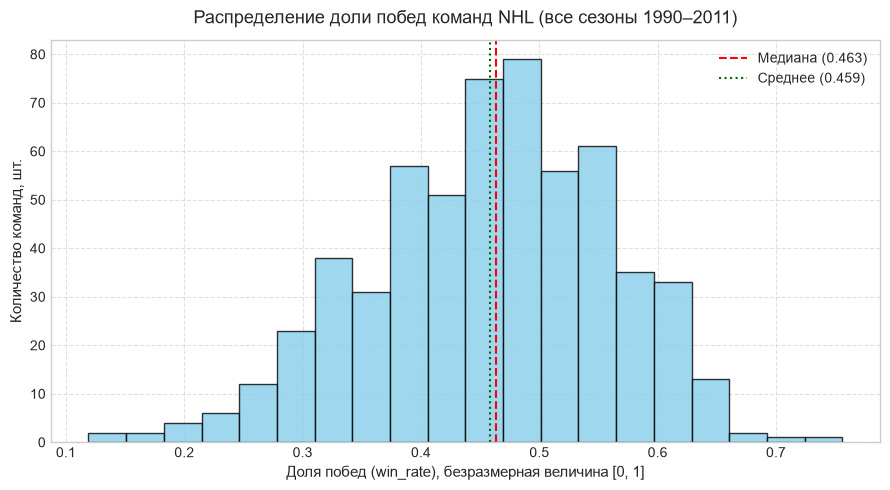

In [14]:
# 3.1. Ваш код
# Добавьте ячейки при необходимости.
plt.figure(figsize=(9, 5))
plt.hist(df['win_rate'], bins=20, color='skyblue', edgecolor='black', alpha=0.8)

plt.axvline(df['win_rate'].median(), color='red', linestyle='--', linewidth=1.5, label=f'Медиана ({df["win_rate"].median():.3f})')
plt.axvline(df['win_rate'].mean(), color='darkgreen', linestyle=':', linewidth=1.5, label=f'Среднее ({df["win_rate"].mean():.3f})')

plt.title('Распределение доли побед команд NHL (все сезоны 1990–2011)', fontsize=13, pad=12)
plt.xlabel('Доля побед (win_rate), безразмерная величина [0, 1]', fontsize=11)
plt.ylabel('Количество команд, шт.', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Ответ 3.1:**

На графике видно, что результаты большинства команд собираются в районе середины - примерно от 0.40 до 0.55 (то есть команды обычно выигрывают от 40% до 55% своих матчей). Это подтверждают числа из пункта 2.1: медиана равна 0.463, а среднее - 0.459. Слишком слабые результаты (меньше 0.20, как у Ottawa Senators в 1992 году с 0.119) или слишком сильные (больше 0.70, как у Detroit Red Wings в 1995 году с 0.756) встречаются очень редко - на графике по краям совсем маленькие столбики.

## 3.2. Покажите изменение по годам: 8 баллов

Постройте линейный график медианы `win_rate` по годам из пункта 2.2.
        Подпишите оси. Найдите один год с заметно большей или меньшей медианой,
        чем у соседних доступных лет, и приведите числа. Отметьте в объяснении
        годы без данных.

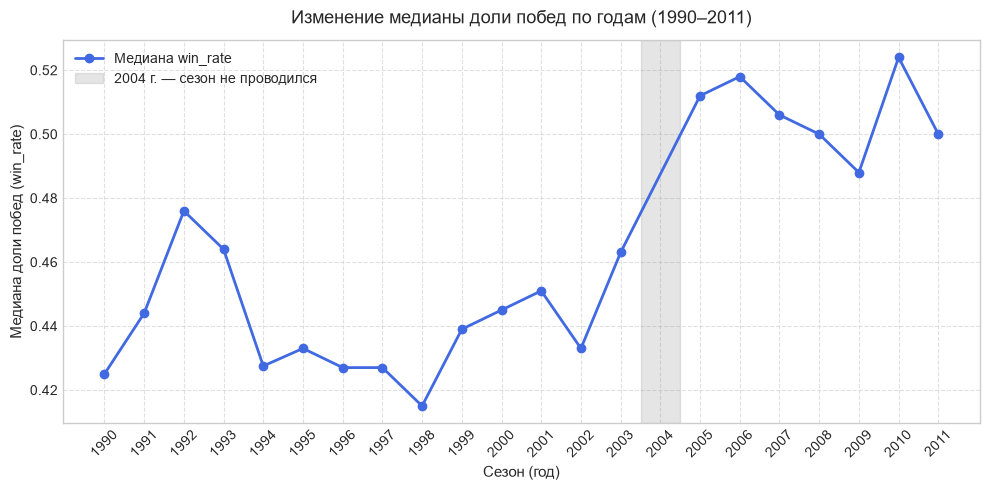

In [15]:
# 3.2. Ваш код
# Добавьте ячейки при необходимости.
plt.figure(figsize=(10, 5))

# линия изменения медианы доли побед по годам
plt.plot(season_stats['year'], season_stats['winrate_median'], marker='o', color='royalblue', linewidth=2, label='Медиана win_rate')

# Серым цвет - пропущенный 2004 год (когда сезона не было)
plt.axvspan(2003.5, 2004.5, color='gray', alpha=0.2, label='2004 г. — сезон не проводился')

plt.title('Изменение медианы доли побед по годам (1990–2011)', fontsize=13, pad=12)
plt.xlabel('Сезон (год)', fontsize=11)
plt.ylabel('Медиана доли побед (win_rate)', fontsize=11)
plt.xticks(range(int(season_stats['year'].min()), int(season_stats['year'].max()) + 1), rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

**Ответ 3.2:**

До 2003 года медиана доли побед держалась ниже (в диапазоне 0.415–0.476), а с 2005 года закрепилась выше - около 0.50–0.52 из-за отмены ничьих. В качестве года с заметным отличием выделяется 1998 год, когда медиана просела до минимума 0.4150 (для сравнения, в 1997 году было 0.4270, а в 1999 - 0.4390). Другим заметным пиком стал 2010 год с максимумом 0.5240 на фоне соседних 2009 (0.4880) и 2011 (0.5000) годов.   При этом в данных полностью отсутствует 2004 год (сезон был отменён из-за локаута), поэтому на графике он наглядно показан разрывом с серой полосой. 

## 3.3. Сравните голы и долю побед: 8 баллов

Постройте диаграмму рассеяния: `goal_diff` по горизонтали,
        `win_rate` по вертикали. Опишите общую связь и приведите две конкретные
        строки для иллюстрации. Можно ли по этому графику заключить, что знак
        `goal_diff` безошибочно определяет высокую долю побед?

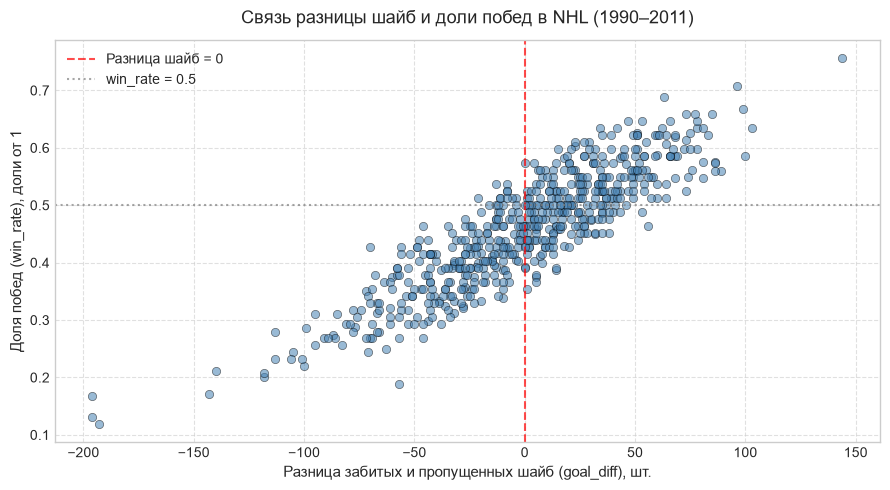

Пример 1 (goal_diff > 0, но win_rate < 0.5):


,team,year,goals_for,goals_against,goal_diff,wins,win_rate
152,Detroit Red Wings,1996,253,197,56,38,0.463



Пример 2 (goal_diff < 0, но win_rate >= 0.5):


,team,year,goals_for,goals_against,goal_diff,wins,win_rate
385,Los Angeles Kings,2005,249,270,-21,42,0.512


In [16]:
# 3.3. Ваш код
# Добавьте ячейки при необходимости.
plt.figure(figsize=(9, 5))
plt.scatter(df['goal_diff'], df['win_rate'], alpha=0.55, color='steelblue', edgecolor='black', linewidth=0.5)

# Ориентиры: нулевая разница шайб и 50% побед
plt.axvline(0, color='red', linestyle='--', alpha=0.7, label='Разница шайб = 0')
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.7, label='win_rate = 0.5')

plt.title('Связь разницы шайб и доли побед в NHL (1990–2011)', fontsize=13, pad=12)
plt.xlabel('Разница забитых и пропущенных шайб (goal_diff), шт.', fontsize=11)
plt.ylabel('Доля побед (win_rate), доли от 1', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# 1) Разница голов > 0, но доля побед < 0.5
ex1 = df[(df['goal_diff'] > 0) & (df['win_rate'] < 0.5)].sort_values('goal_diff', ascending=False).head(1)
# 2) Разница голов < 0, но доля побед >= 0.5
ex2 = df[(df['goal_diff'] < 0) & (df['win_rate'] >= 0.5)].sort_values('goal_diff').head(1)

print("Пример 1 (goal_diff > 0, но win_rate < 0.5):")
display(ex1[['team', 'year', 'goals_for', 'goals_against', 'goal_diff', 'wins', 'win_rate']])

print("\nПример 2 (goal_diff < 0, но win_rate >= 0.5):")
display(ex2[['team', 'year', 'goals_for', 'goals_against', 'goal_diff', 'wins', 'win_rate']])

**Ответ 3.3:**

На графике видно сильную прямую связь: чем лучше у команды разница шайб (goal_diff), тем выше её доля побед (win_rate) - все точки идут плотной диагональной полосой снизу вверх. Однако знак разницы шайб не определяет долю побед безошибочно: У Detroit Red Wings в 1996 году разница шайб была отличной (+56), но доля побед составила всего 0.463 (меньше половины). А у Los Angeles Kings в 2005 году разница была отрицательной (-21), но доля побед превысила половину - 0.512 (42 победы). Это происходит из-за того, что команда может часто выигрывать с перевесом всего в 1 шайбу, но иногда крупно проигрывать отдельные матчи.

## 3.4. Покажите историю выбранной команды: 7 баллов

Для команды из пункта 2.4 постройте график `win_rate` по годам.
        Укажите в ответе, есть ли годы без данных, и как вы показали их на графике.
        Найдите два соседних доступных сезона с заметным изменением
        и укажите значения в ответе.

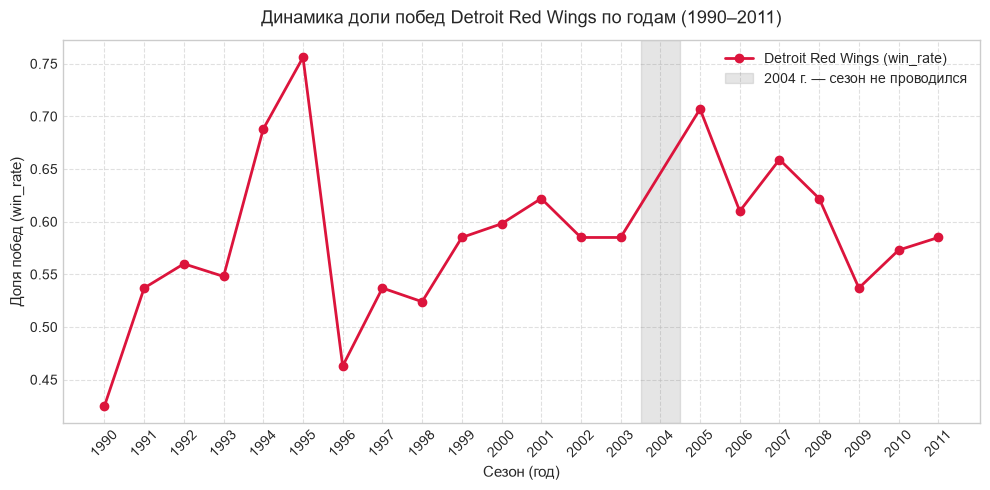

Максимальный перепад между соседними доступными сезонами:
1995 г.: win_rate = 0.756
1996 г.: win_rate = 0.463
Разница: 0.293


In [17]:
# 3.4. Ваш код
# Добавьте ячейки при необходимости.
plt.figure(figsize=(10, 5))

# график для Detroit Red Wings
plt.plot(team_df['year'], team_df['win_rate'], marker='o', color='crimson', linewidth=2, label='Detroit Red Wings (win_rate)')

# пропуск 2004 года
plt.axvspan(2003.5, 2004.5, color='gray', alpha=0.2, label='2004 г. — сезон не проводился')

plt.title('Динамика доли побед Detroit Red Wings по годам (1990–2011)', fontsize=13, pad=12)
plt.xlabel('Сезон (год)', fontsize=11)
plt.ylabel('Доля побед (win_rate)', fontsize=11)
plt.xticks(range(int(team_df['year'].min()), int(team_df['year'].max()) + 1), rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

team_df['diff_with_prev'] = team_df['win_rate'].diff().abs()
biggest_jump_idx = team_df['diff_with_prev'].idxmax()

prev_row = team_df.loc[biggest_jump_idx - 1]
curr_row = team_df.loc[biggest_jump_idx]
print(f"Максимальный перепад между соседними доступными сезонами:")
print(f"{int(prev_row['year'])} г.: win_rate = {prev_row['win_rate']:.3f}")
print(f"{int(curr_row['year'])} г.: win_rate = {curr_row['win_rate']:.3f}")
print(f"Разница: {abs(curr_row['win_rate'] - prev_row['win_rate']):.3f}")

**Ответ 3.4:**

На графике представлена динамика доли побед команды Detroit Red Wings за все 21 сезона. В данных отсутствует 2004 год (сезон был отменён из-за локаута), поэтому на графике этот промежуток показан разрывом с серой полосой. Самое резкое изменение произошло между соседними сезонами 1995 и 1996 годов:
- В 1995 году команда показала свой рекордный win_rate - 0.756;
- В 1996 году показатель резко упал до 0.463 (разница составила внушительные 0.293, то есть почти 30% побед).   

## 4.1. Проверьте последовательность лет: 5 баллов

Найдите все годы между минимальным и максимальным `year`,
        которых нет в таблице. Как отсутствие года может повлиять на линейный график?
        Сошлитесь на свой график из пункта 3.2.

In [18]:
# 4.1. Ваш код
# Добавьте ячейки при необходимости.
all_years = set(range(df['year'].min(), df['year'].max() + 1))
actual_years = set(df['year'].unique())
missing_years = sorted(list(all_years - actual_years))
print(f"Минимальный год: {df['year'].min()}, максимальный: {df['year'].max()}")
print(f"Пропущенные годы в диапазоне: {missing_years}")

Минимальный год: 1990, максимальный: 2011
Пропущенные годы в диапазоне: [2004]


**Ответ 4.1:**

Между минимальным 1990 годом и максимальным 2011 годом в таблице пропущен ровно один год - 2004. Если на линейном графике просто соединить соседние точки 2003 года (со значением 0.4630) и 2005 года (со значением 0.5120), у читателя возникнет ложное ощущение, что турнир шел непрерывно и показатели росли плавно. На самом деле сезон 2004/2005 был полностью отменен из-за локаута. Поэтому на нашем графике в пункте 3.2 этот пропуск был специально выделен отдельным серым интервалом на шкале времени, чтобы честно показать отсутствие сезона и не искажать реальную динамику лиги.

## 4.2. Сравните число побед и долю: 6 баллов

Возьмите одну команду, которая есть в 1993, 1994 и 1995 годах.
        Выведите для неё `wins` и `win_rate` за эти годы.
        Какой вывод изменится, если смотреть только на число побед?
        Свяжите ответ с группировкой из пункта 2.2.

In [19]:
# 4.2. Ваш код
# Добавьте ячейки при необходимости.
detroit_lockout = df[(df['team'] == 'Detroit Red Wings') & (df['year'].isin([1993, 1994, 1995]))]
display(detroit_lockout[['team', 'year', 'wins', 'losses', 'win_rate']])

,team,year,wins,losses,win_rate
73,Detroit Red Wings,1993,46,30,0.548
99,Detroit Red Wings,1994,33,11,0.688
126,Detroit Red Wings,1995,62,13,0.756


**Ответ 4.2:**

Для команды Detroit Red Wings в 1993 году зафиксировано 46 побед и доля побед 0.548, в 1994 году число побед упало до 33, но доля побед выросла до 0.688, а в 1995 году число побед составило 62 при доле побед 0.756. Если смотреть только на количество побед, кажется, что в 1994 году команда пережила тяжелый спад, ведь она выиграла на 13 матчей меньше, чем годом ранее. Однако нормированный показатель win_rate показывает прямо противоположное: качество игры Детройта резко улучшилось почти на 14% побед. Этот вывод полностью совпадает с результатами группировки всей лиги в пункте 2.2, где медиана побед в 1994 году рухнула с 39.0 до 20.5 исключительно из-за сокращения сезона до 48 матчей, тогда как средняя доля побед осталась прежней.

## 4.3. Найдите собственное наблюдение: 5 баллов

Найдите ещё один интересный вам пример в таблице или на графике.
        Укажите команду, год, два значения и пункт, результат которого
        помог вам заметить пример. Как он уточняет ваш общий вывод?

In [20]:
# 4.3. Ваш код
# Добавьте ячейки при необходимости.
detroit_obs = df[(df['team'] == 'Detroit Red Wings') & (df['year'].isin([1995, 1996]))]
display(detroit_obs[['team', 'year', 'wins', 'win_rate', 'goal_diff']])

,team,year,wins,win_rate,goal_diff
126,Detroit Red Wings,1995,62,0.756,144
152,Detroit Red Wings,1996,38,0.463,56


**Ответ 4.3:**

Очень показательным примером выступает Detroit Red Wings в 1996 году, где доля побед составила всего 0.463, а разница шайб при этом была внушительной и положительной - +56 голов. Обратить внимание на этот случай помог график рассеяния из пункта 3.3, где данная строка попала в правый нижний сектор аномалий (положительная разность голов при доле побед ниже 50%). Этот пример существенно уточняет общий вывод о связи голов и побед: уверенный перевес по забитым шайбам не гарантирует лидерства по победам, так как команда могла громить соперников в отдельных играх, но в регулярном чемпионате набрала много ничьих и поражений с разницей всего в одну шайбу.

## 4.4. Сформулируйте выводы: 4 баллов

Сформулируйте два вывода из своей работы. Для каждого приведите
        номер таблицы или графика и одно число. Назовите одно ограничение данных,
        которое важно помнить при чтении результатов.

In [ ]:
# 4.4. Ваш код
# Добавьте ячейки при необходимости.

**Ответ 4.4:**

Первый вывод заключается в том, что успешность спортивных команд лиги имеет выраженное центральное распределение и нормируется регламентом турнира, что подтверждается гистограммой 3.1, где типичная доля побед собирается около медианы 0.463. Второй вывод состоит в том, что при анализе многолетних результатов ориентироваться на абсолютное число побед нельзя без учета регламента, так как по таблице 2.2 в сокращенном сезоне 1994 года медиана побед просела до 20.5, хотя средний уровень команд по доле побед остался стабильным (0.4275). Главным же ограничением исходного датасета является отсутствие информации о количестве фактически сыгранных матчей в сезоне и результатов матчей плей-офф, из-за чего локаутные сезоны без внешнего контекста выглядят провальными, а итоговый чемпион Кубка Стэнли остается неизвестным.